<a href="https://colab.research.google.com/github/Dahmani2020/Biology_DataScience_portfolio/blob/main/Clinical_Risk_Prediction_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Core libraries
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn preprocessing & modeling
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix

# Install and import SHAP for model interpretability
!pip install -q shap
import shap

# Styling
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 120
print("Libraries loaded successfully!")

Libraries loaded successfully!


In [2]:
np.random.seed(42)
n_samples = 1000

# Simulate clinical features
data = {
    'Age': np.random.randint(21, 80, size=n_samples),
    'BMI': np.random.normal(28.5, 5.0, size=n_samples),
    'Glucose': np.random.normal(120, 30, size=n_samples),
    'BloodPressure': np.random.normal(72, 12, size=n_samples),
    'Cholesterol': np.random.normal(210, 40, size=n_samples),
    'Insulin': np.random.exponential(80, size=n_samples),
}

df = pd.DataFrame(data)

# Introduce a biological risk rule to create a realistic target variable (Outcome: 1 = High Risk/Disease, 0 = Low Risk)
risk_score = (
    (df['Age'] > 50).astype(int) * 1.5 +
    (df['BMI'] > 30).astype(int) * 1.2 +
    (df['Glucose'] > 140).astype(int) * 2.5 +
    (df['Cholesterol'] > 240).astype(int) * 1.0 +
    np.random.normal(0, 1, size=n_samples)
)
df['Disease_Risk'] = (risk_score > 3.0).astype(int)

print(f"Dataset Shape: {df.shape}")
print(df.head())
print("\nClass Distribution:")
print(df['Disease_Risk'].value_counts(normalize=True))

Dataset Shape: (1000, 7)
   Age        BMI     Glucose  BloodPressure  Cholesterol     Insulin  \
0   59  35.483968  120.893378      55.114512   205.344373  102.044698   
1   72  26.550448   94.560604      67.537522   154.304419   57.727579   
2   49  34.248115  125.220557      91.147318   252.221784   74.462361   
3   35  31.126059  127.372019      91.610343   320.028921   79.947739   
4   63  29.667329   94.158489      54.262235   189.399669   59.901275   

   Disease_Risk  
0             0  
1             0  
2             1  
3             0  
4             0  

Class Distribution:
Disease_Risk
0    0.698
1    0.302
Name: proportion, dtype: float64


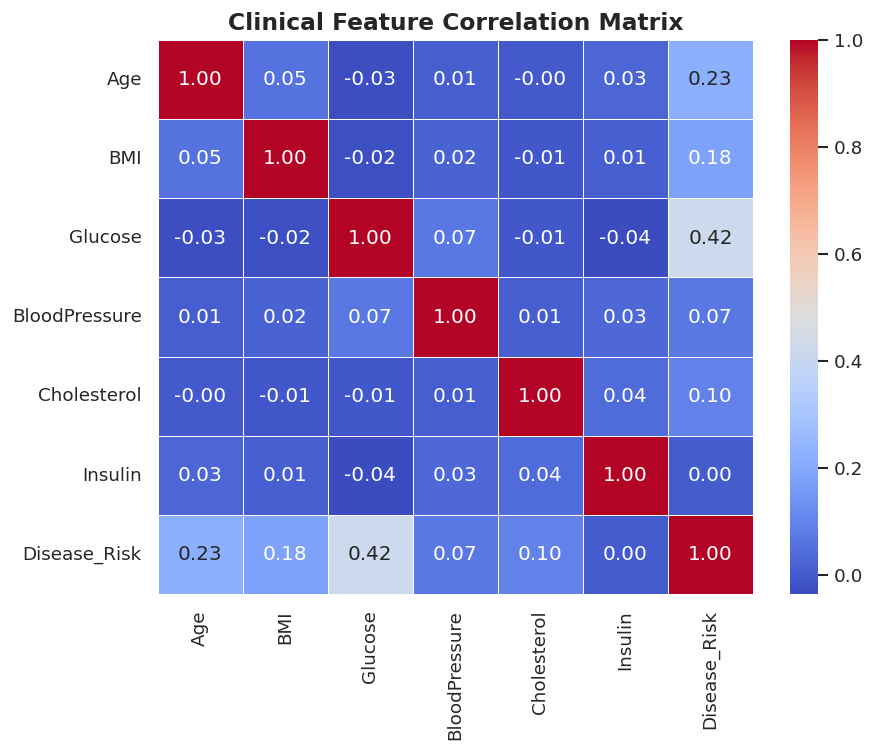

/tmp/ipykernel_1671/2716555095.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Disease_Risk', y='Glucose', data=df, palette=['#3498db', '#e74c3c'])


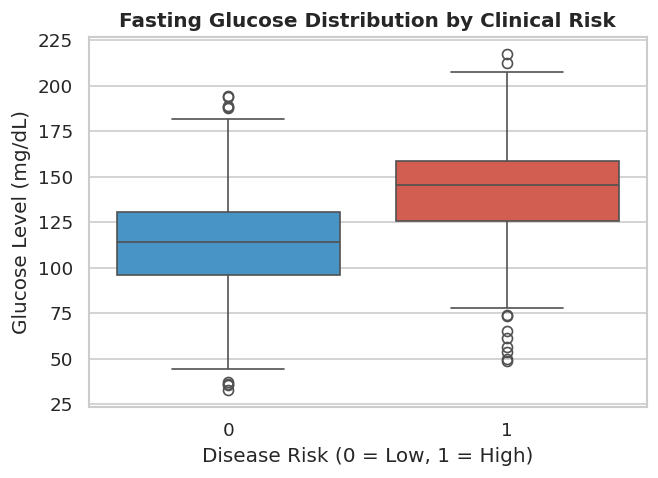

In [3]:
# Correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Clinical Feature Correlation Matrix', fontsize=14, fontweight='bold')
plt.show()

# Boxplot comparing Glucose levels across risk groups
plt.figure(figsize=(6, 4))
sns.boxplot(x='Disease_Risk', y='Glucose', data=df, palette=['#3498db', '#e74c3c'])
plt.title('Fasting Glucose Distribution by Clinical Risk', fontsize=12, fontweight='bold')
plt.xlabel('Disease Risk (0 = Low, 1 = High)')
plt.ylabel('Glucose Level (mg/dL)')
plt.show()

In [4]:
# Split features and target
X = df.drop(columns=['Disease_Risk'])
y = df['Disease_Risk']

# Train-Test Split (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale numerical features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrames for convenience
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X.columns)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (800, 6)
Testing set shape: (200, 6)


In [5]:
# 1. Baseline Model: Logistic Regression
lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train_scaled, y_train)
lr_preds = lr_model.predict(X_test_scaled)
lr_probs = lr_model.predict_proba(X_test_scaled)[:, 1]

# 2. Advanced Model: Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train) # Tree models don't strictly require scaling
rf_preds = rf_model.predict(X_test)
rf_probs = rf_model.predict_proba(X_test)[:, 1]

print("Models trained successfully!")

Models trained successfully!


--- Logistic Regression Performance ---
Accuracy:  0.8000
Precision: 0.7381
Recall:    0.5167 (Crucial for medical diagnostics)
F1-Score:  0.6078
ROC-AUC:   0.8398

--- Random Forest Performance ---
Accuracy:  0.8600
Precision: 0.8478
Recall:    0.6500 (Crucial for medical diagnostics)
F1-Score:  0.7358
ROC-AUC:   0.9137



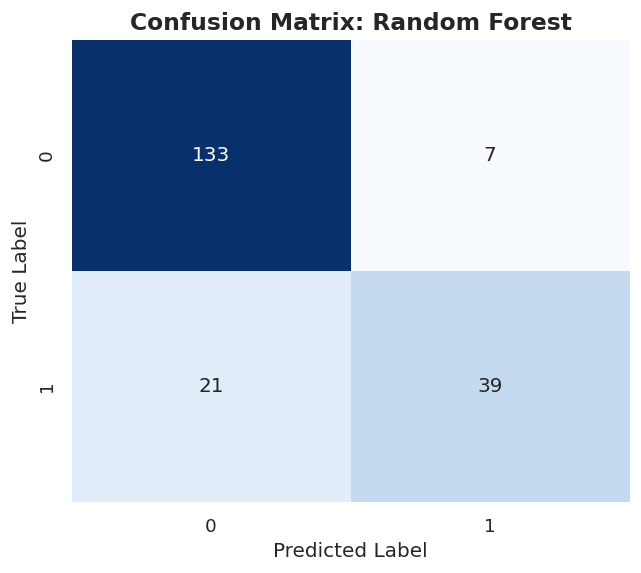

In [6]:
def evaluate_model(y_true, y_pred, y_probs, model_name):
    print(f"--- {model_name} Performance ---")
    print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision: {precision_score(y_true, y_pred):.4f}")
    print(f"Recall:    {recall_score(y_true, y_pred):.4f} (Crucial for medical diagnostics)")
    print(f"F1-Score:  {f1_score(y_true, y_pred):.4f}")
    print(f"ROC-AUC:   {roc_auc_score(y_true, y_probs):.4f}\n")

evaluate_model(y_test, lr_model.predict(X_test_scaled), lr_probs, "Logistic Regression")
evaluate_model(y_test, rf_preds, rf_probs, "Random Forest")

# Confusion Matrix for Random Forest
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, rf_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix: Random Forest', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

/tmp/ipykernel_1671/2099466293.py:7: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test, plot_type="bar", show=False)
/usr/local/lib/python3.13/dist-packages/shap/plots/_beeswarm.py:723: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  summary_legacy(
/usr/local/lib/python3.13/dist-packages/shap/plots/_beeswarm.py:743: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  summary_legacy(


<Figure size 1200x720 with 0 Axes>

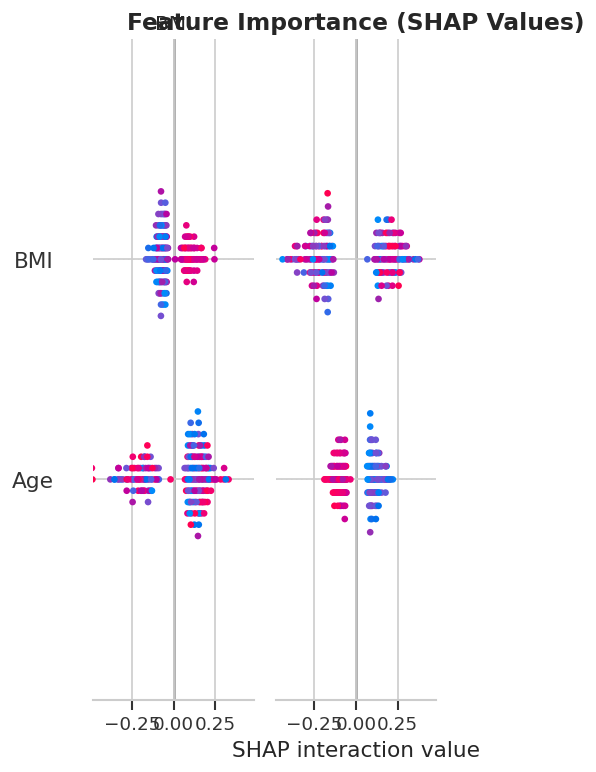

In [7]:
# Initialize SHAP Tree Explainer for Random Forest
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test)

# Summary Plot showing feature impact
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, plot_type="bar", show=False)
plt.title('Feature Importance (SHAP Values)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()